# 04 · Complete data in the window

Collector coverage varies: ganglia disappears for weeks, IPMI is almost always there. Since the
failure rate also changes from month to month, gaps would act as a clock, so the study works on
jobs with **complete data in the 20-minute window**. This notebook

1. measures, for every job and channel, the fraction of expected readings present in the window;
2. applies the procedure fixed in advance (P3 in [`DECISOES.md`](../DECISOES.md)) to choose the rule;
3. shows how complete data depends on month and on job state.

Output: `data/completeness.parquet` (one row per GPU job: fractions and flags).

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tcc.config import DATA, FLOOR, RESULTS, STATES, WINDOW_S, source
from tcc.splits import temporal_splits

jobs = pd.read_parquet(DATA / "jobs.parquet")                 # reference cohort (69,096 jobs)
inv = pd.read_csv(RESULTS / "channel_inventory.csv", index_col="channel")
used = inv.index[~inv.constant].tolist()                       # the 17 channels
windows = pd.read_parquet(DATA / "windows.parquet")              # one row per (job, node), from notebook 02

## Fraction of expected readings

For a channel with cadence *c*, a node is expected to deliver 1200 / *c* readings in the
window. The fraction of a node is `min(readings, expected) / expected`; the fraction of a job is
the **mean over its nodes** (a missing node of a 16-node job costs 1/16). Completeness is never
measured over the whole job, which would select by duration.

The **typical delivery** of a channel is the median fraction over the (job, node) windows that
have at least one reading: what a node that is reporting normally delivers.

In [2]:
frac, typical = {}, {}
for c in used:
    r = pd.read_parquet(DATA / "raw_windows" / f"{c}.parquet", columns=["job_id", "node", "ts"])
    n = r.groupby(["job_id", "node"]).size().rename("n").reset_index()
    w = windows[["job_id", "node"]].merge(n, on=["job_id", "node"], how="left").fillna({"n": 0})
    expected = WINDOW_S / inv.loc[c, "cadence_s"]
    w["f"] = np.minimum(w.n, expected) / expected
    frac[c] = w.groupby("job_id").f.mean()
    reporting = w.loc[w.n > 0, "f"]
    typical[c] = {"source": source(c), "expected": expected, "median": reporting.median(),
                  "p25": reporting.quantile(0.25), "p75": reporting.quantile(0.75),
                  "share_ge_0.80": (reporting >= 0.8).mean()}
F = pd.DataFrame(frac).reindex(jobs.job_id)
typical = pd.DataFrame(typical).T
typical

,source,expected,median,p25,p75,share_ge_0.80
mem_total,ganglia,20.0,1.0,1.0,1.0,0.972409
mem_free,ganglia,30.0,0.833333,0.7,0.966667,0.589422
mem_cached,ganglia,30.0,0.833333,0.7,0.966667,0.589369
mem_buffers,ganglia,30.0,0.833333,0.7,0.966667,0.589672
swap_free,ganglia,30.0,0.833333,0.7,0.966667,0.589304
cpu_wio,ganglia,13.333333,1.0,1.0,1.0,0.982051
proc_run,ganglia,15.0,0.866667,0.8,0.933333,0.779561
load_one,ganglia,13.333333,1.0,1.0,1.0,0.984611
gpu0_core_temp,IPMI,60.0,1.0,1.0,1.0,0.933407
gpu1_core_temp,IPMI,60.0,1.0,1.0,1.0,0.933407


## The rules

| Rule | A job is complete if, in every one of the 17 channels, its fraction is … |
|---|---|
| R80 | ≥ 0.80 (the plan's rule) |
| Rrel | ≥ 0.80 × the channel's typical delivery |
| R1 | > 0: at least one reading |
| R60, R100 | ≥ 0.60, = 1.00 (recorded only, as the plan asks) |

In [3]:
thresholds = {
    "R60": {c: 0.60 for c in used},
    "R80": {c: 0.80 for c in used},
    "R100": {c: 1.00 for c in used},
    "Rrel": {c: 0.80 * typical.loc[c, "median"] for c in used},
    "R1": {c: 1e-6 for c in used},          # the smallest possible positive fraction is ~6.5e-5
}
rule = pd.DataFrame({r: np.all([F[c].values >= th[c] - 1e-9 for c in used], axis=0) for r, th in thresholds.items()},
                    index=F.index)

## Viability of each rule on the GPU cohort

Under each rule we split the complete GPU jobs in time (notebook 06 explains the splits) and
count the positives in each test set. The floor is 100 positives (P2).

In [4]:
gpu = jobs[jobs.gpu].reset_index(drop=True)


def viability(mask):
    P = gpu[mask.reindex(gpu.job_id).values]
    sp = temporal_splits(P)
    Pi = P.set_index("job_id")
    out = {"jobs": len(P), "pos_a": int((P.target_a == 1).sum()), "pos_b": int((P.target_b == 1).sum())}
    for name, d in sp.items():
        test = Pi.loc[d["test"]]
        out[f"{name}_test_pos_a"] = int((test.target_a == 1).sum())
        out[f"{name}_test_pos_b"] = int((test.target_b == 1).sum())
    test = Pi.loc[sp["main"]["test"]]
    out["users_with_failure_in_main_test"] = test.loc[test.target_a == 1, "user_id"].nunique()
    out["min_block_pos_a"] = min(out[f"block{k}_test_pos_a"] for k in (1, 2, 3))
    return out


via = pd.DataFrame({r: viability(rule[r]) for r in rule}).T
via[["jobs", "pos_a", "pos_b", "block1_test_pos_a", "block2_test_pos_a", "block3_test_pos_a",
     "block1_test_pos_b", "block2_test_pos_b", "block3_test_pos_b", "users_with_failure_in_main_test"]]

,jobs,pos_a,pos_b,block1_test_pos_a,block2_test_pos_a,block3_test_pos_a,block1_test_pos_b,block2_test_pos_b,block3_test_pos_b,users_with_failure_in_main_test
R60,18512,2488,1627,392,231,103,80,91,96,23
R80,10581,1595,737,264,84,75,43,53,48,12
R100,1406,397,35,28,33,21,3,0,1,2
Rrel,15408,2168,1267,387,288,97,56,78,75,19
R1,24107,3164,3092,575,227,124,97,585,113,31


## Procedure P3: which rule is primary

Fixed before any count was made:

* **T1, normal data:** a reporting node typically delivers ≥ 80 % of the nominal readings in
  every channel.
* **T2, viability:** every block test keeps at least 100 target-(a) positives.

R80 is primary if it passes T1 and T2; otherwise Rrel, if it passes T2; otherwise R1. The plan's
R80 is then kept as the sensitivity analysis.

In [5]:
T1 = bool((typical["median"] >= 0.80).all())
T2 = (via.min_block_pos_a >= FLOOR).to_dict()
primary = "R80" if (T1 and T2["R80"]) else ("Rrel" if T2["Rrel"] else "R1")
print(f"T1: {T1}\nT2: {T2}\nprimary rule: {primary}")
assert primary == "R1"

forty = typical.index[inv.loc[typical.index, "cadence_s"] == 40]
assert typical.loc[forty, "median"].nunique() == 1
print(f'T1 fails: median delivery {typical.loc[forty, "median"].max():.2f} in the 40 s channels, '
      f'at least {typical.drop(forty)["median"].min():.2f} in the others')
jobs_r1, pos_a, pos_b = (int(via.loc["R1", c]) for c in ("jobs", "pos_a", "pos_b"))
print(f"R1: {jobs_r1:,} complete jobs ({jobs_r1 / len(gpu):.1%} of the GPU cohort), "
      f"{pos_a:,} target-(a) and {pos_b:,} target-(b) positives")

T1: True
T2: {'R60': True, 'R80': False, 'R100': False, 'Rrel': False, 'R1': True}
primary rule: R1
T1 fails: median delivery 0.83 in the 40 s channels, at least 0.87 in the others
R1: 24,107 complete jobs (36.5% of the GPU cohort), 3,164 target-(a) and 3,092 target-(b) positives


## Completeness rules

In [6]:
definition = {"R80": "≥ 80 % in every channel (plan)", "Rrel": "≥ 80 % of typical delivery",
        "R1": "≥ 1 reading in every channel", "R60": "≥ 60 % (record only)", "R100": "100 % (record only)"}
outcome = {"R80": "fails T2", "Rrel": "fails T2", "R1": "primary", "R60": "not in procedure", "R100": "fails T2"}
rules = pd.DataFrame([{"rule": r, "definition": definition[r], "jobs": via.loc[r, "jobs"],
                       "block_test_pos_a": "/".join(str(via.loc[r, f"block{k}_test_pos_a"]) for k in (1, 2, 3)),
                       "block_test_pos_b": "/".join(str(via.loc[r, f"block{k}_test_pos_b"]) for k in (1, 2, 3)),
                       "users_with_failure_in_main_test": via.loc[r, "users_with_failure_in_main_test"],
                       "outcome": outcome[r]} for r in definition]).set_index("rule")
rules.to_csv(RESULTS / "completeness_rules.csv")
rules

,definition,jobs,block_test_pos_a,block_test_pos_b,users_with_failure_in_main_test,outcome
rule,,,,,,
R80,≥ 80 % in every channel (plan),10581,264/84/75,43/53/48,12,fails T2
Rrel,≥ 80 % of typical delivery,15408,387/288/97,56/78/75,19,fails T2
R1,≥ 1 reading in every channel,24107,575/227/124,97/585/113,31,primary
R60,≥ 60 % (record only),18512,392/231/103,80/91/96,23,not in procedure
R100,100 % (record only),1406,28/33/21,3/0/1,2,fails T2


## Flags for the GPU cohort

* `complete`: rule R1 (primary population);
* `complete_strict`: rule R80 (sensitivity population);
* `has_ganglia`: at least one reading in every ganglia channel (only for the secondary baseline);
* `has_ipmi`: the same for IPMI.

In [7]:
flags = pd.DataFrame({"job_id": gpu.job_id})
Fg = F.reindex(gpu.job_id)
for c in used:
    flags[f"frac_{c}"] = Fg[c].values
flags["complete"] = rule["R1"].reindex(gpu.job_id).values.astype(int)
flags["complete_strict"] = rule["R80"].reindex(gpu.job_id).values.astype(int)
ganglia = [c for c in used if source(c) == "ganglia"]
ipmi = [c for c in used if source(c) == "IPMI"]
flags["has_ganglia"] = (Fg[ganglia] > 0).all(axis=1).values.astype(int)
flags["has_ipmi"] = (Fg[ipmi] > 0).all(axis=1).values.astype(int)
assert (flags.complete_strict <= flags.complete).all()
flags.to_parquet(DATA / "completeness.parquet", index=False)

print(f"IPMI present (all 9 channels) in the GPU cohort: {flags.has_ipmi.mean():.1%}")

IPMI present (all 9 channels) in the GPU cohort: 98.9%


## Coverage over time

Share of GPU jobs started each day with at least one reading in every channel of the source.
IPMI is almost always there; ganglia disappears for weeks.

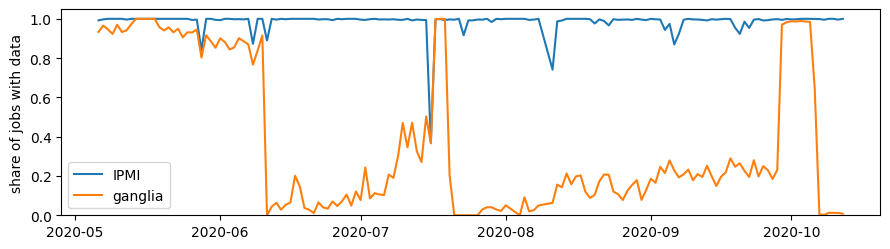

In [8]:
C = gpu.merge(flags, on="job_id")
day = C.start_time.dt.floor("D")
daily = C.groupby(day)[["has_ipmi", "has_ganglia"]].mean()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(daily.index, daily.has_ipmi, color="C0", label="IPMI")
ax.plot(daily.index, daily.has_ganglia, color="C1", label="ganglia")
ax.set_ylabel("share of jobs with data")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left")
plt.tight_layout()

In [9]:
C["month"] = C.start_time.dt.strftime("%Y-%m")
by_month = C.groupby("month").complete.mean()
print((100 * by_month).round(1).to_string())

month
2020-05    93.1
2020-06    33.9
2020-07    28.4
2020-08    12.3
2020-09    28.0
2020-10    54.9


The failure rate drifts too. Monthly target-(a) failure rate in the complete subset (by month of
the end time):

In [10]:
comp = C[C.complete == 1]
rate = comp.groupby(comp.end_time.dt.strftime("%Y-%m")).target_a.mean()
print((100 * rate).round(1).to_string())

end_time
2020-05     9.4
2020-06    25.3
2020-07     8.6
2020-08    13.1
2020-09    20.8
2020-10    13.9


## Is complete data linked to the label?

Raw shares differ by state. But states are not spread evenly in time, and coverage changes with
time. So each job is compared with the jobs **started on the same day and of the same type**
(single- or multi-node): the *excess* of a state is its mean of
`complete − mean(complete of the same day and type)`.

In [11]:
C["day"] = C.start_time.dt.strftime("%Y-%m-%d")
C["multi_node"] = (C.num_nodes_alloc > 1).astype(int)
C["excess_same_day"] = C.complete - C.groupby("day").complete.transform("mean")
C["excess_same_day_type"] = C.complete - C.groupby(["day", "multi_node"]).complete.transform("mean")
sel = C.groupby("job_state").agg(jobs=("complete", "size"), complete_share=("complete", "mean"),
                                 excess_same_day=("excess_same_day", "mean"),
                                 excess_same_day_type=("excess_same_day_type", "mean")).reindex(STATES)
sel.style.format({"complete_share": "{:.1%}", "excess_same_day": "{:+.1%}", "excess_same_day_type": "{:+.1%}"})

,jobs,complete_share,excess_same_day,excess_same_day_type
job_state,,,,
COMPLETED,50575,35.3%,-1.3%,-0.3%
FAILED,7455,39.9%,+0.6%,+0.3%
OUT_OF_MEMORY,398,15.8%,-4.0%,-0.5%
NODE_FAIL,134,94.0%,+3.2%,+2.1%
TIMEOUT,7455,41.5%,+8.5%,+1.6%


In [12]:
print(f"largest |excess| against jobs of the same day and type: {100 * sel.excess_same_day_type.abs().max():.1f} pp")

largest |excess| against jobs of the same day and type: 2.1 pp


## Populations

* **Complete** (R1): the primary population.
* **GPU cohort**: used only for the IPMI groups, as a selection test (notebook 08).
* **Strict** (R80): the sensitivity population.

In [13]:
pops = [("Reference (all jobs)", jobs), ("GPU cohort (secondary)", C),
        ("Complete (primary)", C[C.complete == 1]), ("Strict ≥ 80 % (sensitivity)", C[C.complete_strict == 1])]
populations = pd.DataFrame([{"population": name, "jobs": len(P), "users": P.user_id.nunique(),
                             "pos_a": int((P.target_a == 1).sum()), "prev_a": P.target_a.mean(),
                             "pos_b": int((P.target_b == 1).sum()), "prev_b": P.target_b.mean()}
                            for name, P in pops]).set_index("population")
populations.to_csv(RESULTS / "populations.csv")
populations.style.format({"jobs": "{:,}", "pos_a": "{:,}", "pos_b": "{:,}", "prev_a": "{:.1%}", "prev_b": "{:.1%}"})

,jobs,users,pos_a,prev_a,pos_b,prev_b
population,,,,,,
Reference (all jobs),"69,096",392,"8,224",13.4%,"7,905",13.0%
GPU cohort (secondary),"66,017",345,"7,987",13.6%,"7,455",12.8%
Complete (primary),"24,107",294,"3,164",15.1%,"3,092",14.8%
Strict ≥ 80 % (sensitivity),"10,581",216,"1,595",16.2%,737,8.2%
